# Self-Attention from Scratch

A minimal, single-head **causal self-attention** block in PyTorch, following *Attention Is All You Need* (Vaswani et al., 2017), Section 3.2.1, Eq. 1:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Most tutorials set every dimension to the same value, which hides what each projection does. Here every dimension is **different on purpose**, so each shape tells you where it came from:

| Symbol | Value | Meaning |
|---|---|---|
| `seq_len` | 3 | tokens in the sentence *"I am good"* |
| `d_model` | 4 | embedding / residual stream width |
| `d_k` | 2 | query and key width (only Q and K must match) |
| `d_v` | 5 | value width (independent of `d_k`) |

> `x` is random. It stands in for the embeddings of *"I am good"*. The weights are untrained, so the attention pattern shows **mechanics**, not meaning.
>
> **In a real model:**
> - `x` comes from a **learned embedding table** (token ID → vector) plus **positional encodings**, not `torch.randn`.
> - `W_q`, `W_k`, `W_v`, `W_o` are **learned by training** on a task such as next-token prediction: compute a loss, backpropagate, and update the weights with an optimizer, over many batches.
> - After training, the attention weights become meaningful. For example, a pronoun attends to the noun it refers to (see Figures 3–5 in the paper).

In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
seq_len = 3   # "I am good"
d_model = 4   # input & output width
d_k = 2       # query & key width
d_v = 5       # value width
tokens = ["I", "am", "good"]

_ = torch.manual_seed(42)

### 0. Input
One `d_model`-wide vector per token.

In [3]:
x = torch.randn(seq_len, d_model)
print(f"0. Input x:              {tuple(x.shape)}  (seq_len, d_model)")

0. Input x:              (3, 4)  (seq_len, d_model)


### 1. Projections
Four learned linear maps. `W_q` and `W_k` project into the same `d_k` space so they can be compared; `W_v` picks its own width `d_v`; `W_o` maps the result back to `d_model`.

In [4]:
W_q = nn.Linear(d_model, d_k, bias=False)  # 4 -> 2
W_k = nn.Linear(d_model, d_k, bias=False)  # 4 -> 2
W_v = nn.Linear(d_model, d_v, bias=False)  # 4 -> 5
W_o = nn.Linear(d_v, d_model, bias=False)  # 5 -> 4
print(f"1. W_q {tuple(W_q.weight.shape)}  W_k {tuple(W_k.weight.shape)}  "
      f"W_v {tuple(W_v.weight.shape)}  W_o {tuple(W_o.weight.shape)}  (out, in)")

1. W_q (2, 4)  W_k (2, 4)  W_v (5, 4)  W_o (4, 5)  (out, in)


### 2. Queries, keys, values
Each token asks a question (**Q**), advertises what it contains (**K**), and carries a payload (**V**).

In [5]:
Q = W_q(x)
K = W_k(x)
V = W_v(x)
print(f"2. Q: {tuple(Q.shape)}  (seq_len, d_k)")
print(f"   K: {tuple(K.shape)}  (seq_len, d_k)")
print(f"   V: {tuple(V.shape)}  (seq_len, d_v)")

2. Q: (3, 2)  (seq_len, d_k)
   K: (3, 2)  (seq_len, d_k)
   V: (3, 5)  (seq_len, d_v)


### 3. Scaled scores
`Q @ K.T` gives one compatibility score per (query, key) pair: (3×2)·(2×3) → (3×3). Dividing by √d_k keeps the scores from growing with `d_k`, which would push softmax into regions with tiny gradients.

In [6]:
scores = Q @ K.T / math.sqrt(d_k)
print(f"3. Scaled scores: {tuple(scores.shape)}  (seq_len, seq_len)")
print(scores.detach().round(decimals=2))

3. Scaled scores: (3, 3)  (seq_len, seq_len)
tensor([[-0.0300,  0.1900, -0.0700],
        [ 0.1000, -0.2100,  0.1400],
        [-0.0800,  0.3900, -0.1500]])


### 4. Causal mask
A token must not look at tokens that come after it. `triu(..., diagonal=1)` marks everything **above** the diagonal: the future.

In [7]:
mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
print("4. Mask (True = future, blocked):")
print(mask)

4. Mask (True = future, blocked):
tensor([[False,  True,  True],
        [False, False,  True],
        [False, False, False]])


### 5. Apply the mask
Blocked positions become −∞, so softmax will turn them into exactly 0.

In [8]:
masked_scores = scores.masked_fill(mask, float("-inf"))
print("5. Masked scores:")
print(masked_scores.detach().round(decimals=2))

5. Masked scores:
tensor([[-0.0300,    -inf,    -inf],
        [ 0.1000, -0.2100,    -inf],
        [-0.0800,  0.3900, -0.1500]])


### 6. Softmax → attention weights
Each row becomes a probability distribution over the tokens that row is allowed to see.

In [9]:
weights = torch.softmax(masked_scores, dim=-1)
assert torch.allclose(weights.sum(dim=-1), torch.ones(seq_len)), "rows must sum to 1"
print(f"6. Attention weights: {tuple(weights.shape)}  (each row sums to 1)")
print(weights.detach().round(decimals=2))

6. Attention weights: (3, 3)  (each row sums to 1)
tensor([[1.0000, 0.0000, 0.0000],
        [0.5700, 0.4300, 0.0000],
        [0.2800, 0.4500, 0.2600]])


### 7. Visualize
Lower-triangular: *"I"* sees only itself, *"am"* sees *I, am*, and *"good"* sees the whole prefix.

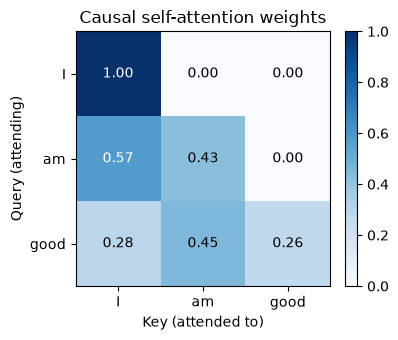

In [10]:
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(weights.detach(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(seq_len), tokens)
ax.set_yticks(range(seq_len), tokens)
ax.set_xlabel("Key (attended to)")
ax.set_ylabel("Query (attending)")
ax.set_title("Causal self-attention weights")
for i in range(seq_len):
    for j in range(seq_len):
        w = weights[i, j].item()
        ax.text(j, i, f"{w:.2f}", ha="center", va="center",
                color="white" if w > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 8. Weighted values
Each output row is a weighted average of the value vectors: (3×3)·(3×5) → (3×5). The width is now `d_v`, not `d_model`.

In [11]:
attn_out = weights @ V
print(f"8. weights @ V: {tuple(attn_out.shape)}  (seq_len, d_v)")

8. weights @ V: (3, 5)  (seq_len, d_v)


### 9. Output projection + residual
`attn_out` is (3×5) but `x` is (3×4), so they can't be added directly. `W_o` maps back to `d_model`, then the residual connection adds the original input.

In [12]:
out = W_o(attn_out)
result = x + out
print(f"9. W_o(attn_out):  {tuple(out.shape)}  (seq_len, d_model)")
print(f"10. x + out:       {tuple(result.shape)}  (seq_len, d_model)")

9. W_o(attn_out):  (3, 4)  (seq_len, d_model)
10. x + out:       (3, 4)  (seq_len, d_model)


## What the full paper adds
This notebook is one attention head. A full Transformer layer also has:

- **Multi-head attention (3.2.2):** h = 8 heads run in parallel with d_k = d_v = d_model / h = 64; their outputs are concatenated and `W_o` maps h·d_v → d_model. Setting h·d_k = d_model is an engineering choice, not a requirement of attention.
- **Add & Norm (3.1):** LayerNorm around each residual connection.
- **Position-wise feed-forward (3.3):** Linear(512 → 2048) → ReLU → Linear(2048 → 512) after attention.
- **Positional encodings (3.5):** without them, attention can't tell word order. Identical tokens get identical vectors wherever they appear.
- **Encoder vs. decoder:** the causal mask above is used in the decoder; the encoder lets every token see the whole sentence.